In [13]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [3]:
data = pd.read_csv('/content/drive/MyDrive/GiveMeSomeCredit.csv')
data

,SeriousDlqin,RevolvingUtilizationOfUnsecuredLines,age,SEX,EDUCATION,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents,NumberOfDefault
0,1,0.878881,40,F,3,0,0.605616,12000.0,19,2,3,11,0.0,1
1,0,1.000000,34,F,1,3,2121.000000,0.0,9,0,2,9,2.0,0
2,0,0.470085,59,F,1,5,1.280078,15916.0,34,6,14,8,0.0,0
3,1,0.908082,26,M,3,3,1.444855,6500.0,22,1,4,8,0.0,2
4,1,1.000000,36,M,3,4,0.913676,2200.0,10,1,1,7,1.0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
149719,0,0.000000,59,F,3,0,0.000000,NaN,2,0,0,0,0.0,0
149720,0,0.000000,66,F,2,0,0.000000,NaN,1,0,0,0,0.0,0
149721,0,0.000000,76,F,2,0,0.000000,NaN,4,0,0,0,NaN,0
149722,0,0.000000,77,F,2,0,0.000000,NaN,2,0,0,0,0.0,0


In [8]:
data['SeriousDlqin'].value_counts()

,count
SeriousDlqin,
0,139845
1,9879


In [9]:
data['SeriousDlqin'].value_counts(normalize=True) * 100

,proportion
SeriousDlqin,
0,93.401859
1,6.598141


In [11]:
features = ['age', 'MonthlyIncome', 'NumberOfTimes90DaysLate']

data[features].isnull().sum()

,0
age,0
MonthlyIncome,29607
NumberOfTimes90DaysLate,0


We selected three features for further analysis: age, monthly income, and the number of times a customer was 90 days late.

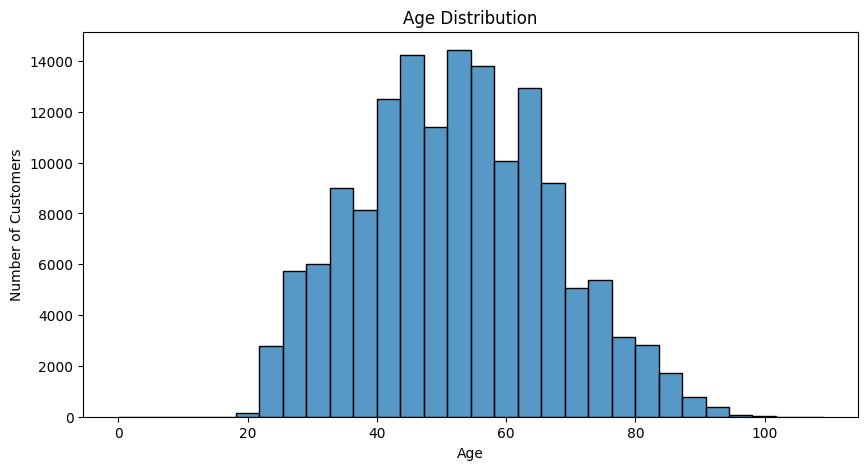

In [14]:
plt.figure(figsize=(10, 5))

sns.histplot(data= data, x='age', bins=30)

plt.title('Age Distribution')
plt.xlabel('Age')
plt.ylabel('Number of Customers')

plt.show()

In [16]:
print("Minimum age:", data['age'].min())
print("Maximum age:", data['age'].max())
print("Zero ages:", (data['age'] == 0).sum())

Minimum age: 0
Maximum age: 109
Zero ages: 1


In [19]:
df = data[
    (data['age'] > 0) &
    (data['age'] <= 100)
].copy()
df

,SeriousDlqin,RevolvingUtilizationOfUnsecuredLines,age,SEX,EDUCATION,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents,NumberOfDefault
0,1,0.878881,40,F,3,0,0.605616,12000.0,19,2,3,11,0.0,1
1,0,1.000000,34,F,1,3,2121.000000,0.0,9,0,2,9,2.0,0
2,0,0.470085,59,F,1,5,1.280078,15916.0,34,6,14,8,0.0,0
3,1,0.908082,26,M,3,3,1.444855,6500.0,22,1,4,8,0.0,2
4,1,1.000000,36,M,3,4,0.913676,2200.0,10,1,1,7,1.0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
149719,0,0.000000,59,F,3,0,0.000000,NaN,2,0,0,0,0.0,0
149720,0,0.000000,66,F,2,0,0.000000,NaN,1,0,0,0,0.0,0
149721,0,0.000000,76,F,2,0,0.000000,NaN,4,0,0,0,NaN,0
149722,0,0.000000,77,F,2,0,0.000000,NaN,2,0,0,0,0.0,0


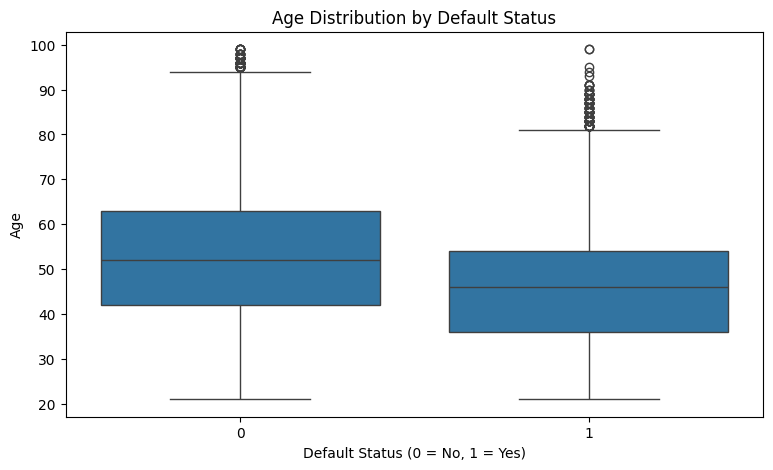

In [20]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data= df,
    x='SeriousDlqin',
    y='age'
)

plt.title('Age Distribution by Default Status')
plt.xlabel('Default Status (0 = No, 1 = Yes)')
plt.ylabel('Age')

plt.show()

In [22]:
df.groupby('SeriousDlqin')['age'].agg(['mean', 'median'])

,mean,median
SeriousDlqin,,
0,52.766498,52.0
1,46.050618,46.0


We used a histogram to examine the age distribution and a boxplot to compare customers based on their default status.

We found one invalid age value (0) and excluded it from the analysis.

Customers with serious delinquency had a lower average age (46.06 years) compared to customers without serious delinquency (52.77 years).

This suggests that age may be associated with credit risk

In [24]:
missing_percentage = df['MonthlyIncome'].isna().mean() * 100

print(f"Missing MonthlyIncome: {missing_percentage:.2f}%")
print("Zero incomes:", (df['MonthlyIncome'] == 0).sum())

Missing MonthlyIncome: 19.77%
Zero incomes: 1627


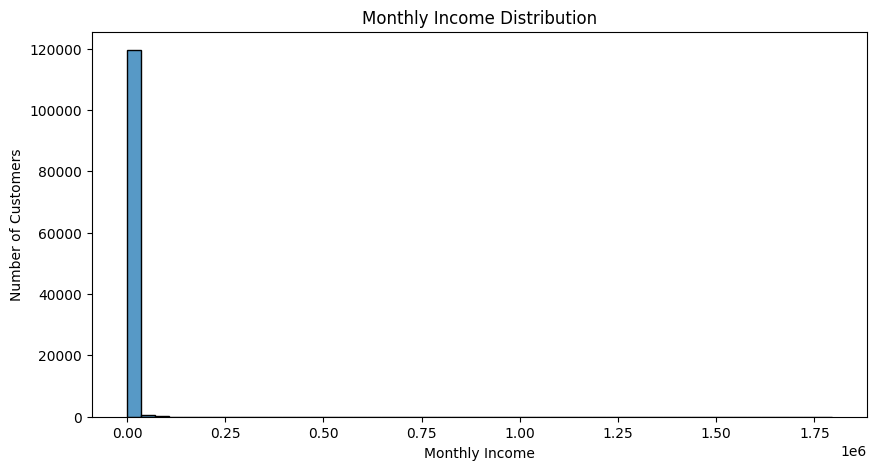

In [27]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x='MonthlyIncome',
    bins=50
)

plt.title('Monthly Income Distribution')
plt.xlabel('Monthly Income')
plt.ylabel('Number of Customers')

plt.show()

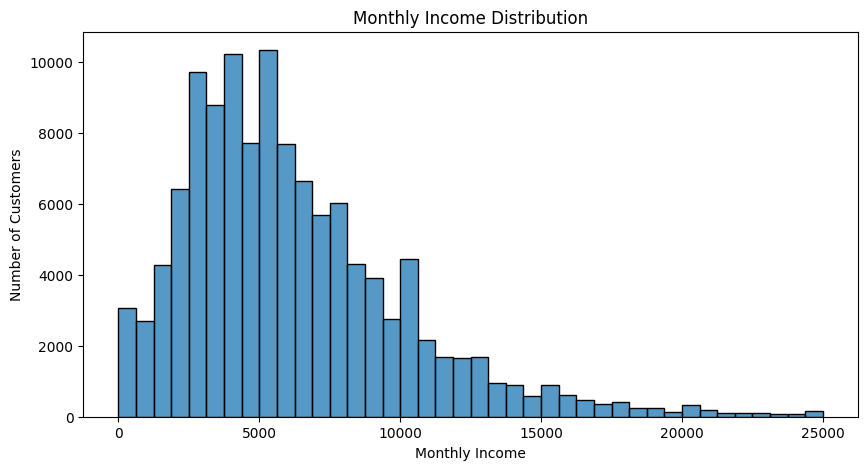

In [33]:
income_limit = df['MonthlyIncome'].quantile(0.99)

plt.figure(figsize=(10, 5))

sns.histplot(
    data=df[df['MonthlyIncome'] <= income_limit],
    x='MonthlyIncome',
    bins=40
)

plt.title('Monthly Income Distribution')
plt.xlabel('Monthly Income')
plt.ylabel('Number of Customers')

plt.show()

In [34]:
df.groupby('SeriousDlqin')['MonthlyIncome'].agg(
    ['count', 'mean', 'median']
)

,count,mean,median
SeriousDlqin,,,
0,111838,6723.214694,5470.0
1,8272,5663.873791,4500.0


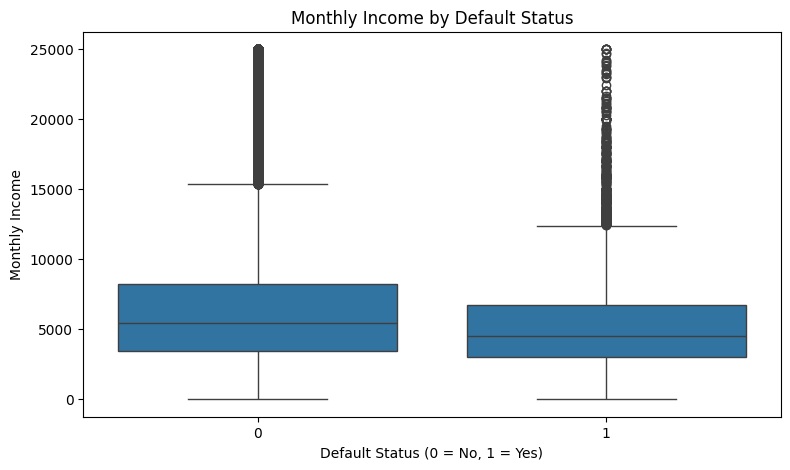

In [35]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df[df['MonthlyIncome'] <= income_limit],
    x='SeriousDlqin',
    y='MonthlyIncome'
)

plt.title('Monthly Income by Default Status')
plt.xlabel('Default Status (0 = No, 1 = Yes)')
plt.ylabel('Monthly Income')

plt.show()

We initially visualized monthly income using all available values. However, a few extremely high incomes stretched the horizontal axis and made the main distribution difficult to observe.

To improve readability, we decided to display income values up to the 99th percentile.

This adjustment was applied only to the visualizations. All income values, including outliers, were preserved in the cleaned dataset for further analysis.

About 20% of the monthly income values were missing, which should be considered when interpreting the results.

Customers with serious delinquency had a lower average monthly income (5,663.87) compared to customers without serious delinquency (6,723.21). The median income showed a similar difference (4,500 vs. 5,470).

These findings suggest that lower monthly income may be associated with higher credit risk. However, income alone is not enough to determine whether a customer will default.

In [37]:
late_counts = df['NumberOfTimes90DaysLate'].value_counts().sort_index()

plt.figure(figsize=(10, 5))

sns.barplot(
    x=late_counts.index,
    y=late_counts.values
)

plt.title('Distribution of 90+ Days Late Payments')
plt.xlabel('Number of Late Payments')
plt.ylabel('Number of Customers')

plt.show()

,count
NumberOfTimes90DaysLate,
0,141642
1,5243
2,1554
3,667
4,291
5,131
6,80
7,38
8,21


In [39]:
late_default_rate = (
    df.groupby('NumberOfTimes90DaysLate')['SeriousDlqin']
    .agg(['count', 'mean'])
)

late_default_rate['mean'] *= 100

late_default_rate

,count,mean
NumberOfTimes90DaysLate,,
0,141642,4.626453
1,5243,33.663933
2,1554,49.935650
3,667,57.721139
4,291,67.010309
5,131,63.358779
6,80,60.000000
7,38,81.578947
8,21,71.428571


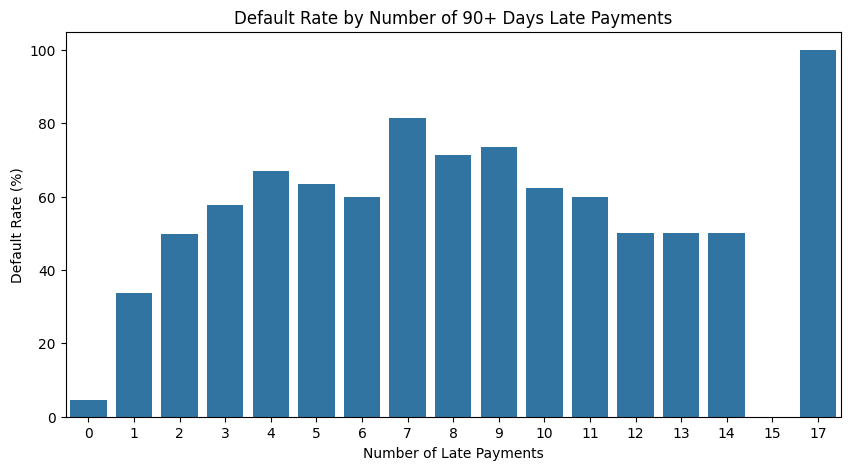

In [40]:
plt.figure(figsize=(10, 5))

sns.barplot(
    x=late_default_rate.index,
    y=late_default_rate['mean']
)

plt.title('Default Rate by Number of 90+ Days Late Payments')
plt.xlabel('Number of Late Payments')
plt.ylabel('Default Rate (%)')

plt.show()

Most customers (141,642) had no recorded payments that were 90 days or more late. As the number of late payments increased, the number of customers decreased significantly.

The default rate was only 4.63% for customers with no late payments, but it increased to 33.66% for customers with one late payment and 49.94% for customers with two late payments.

Customers with four late payments had a default rate of 67.01%.

These results suggest a strong relationship between payment history and credit risk. Customers with more late payments generally had higher default rates.

However, groups with many late payments contained very few customers, making their default rates less reliable.

### Final Insights

I would select `age`, `MonthlyIncome`, and `NumberOfTimes90DaysLate` as the three starting features for credit risk analysis. Age and monthly income showed noticeable differences between customers with and without serious delinquency, while the number of 90+ days late payments showed a strong association with default risk. Among these features, payment history appears particularly informative because default rates increased substantially with the number of late payments.

